7

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

print(f"Number of samples: {X.shape[0]}")
print(f"Number of main features: {X.shape[1]}")

Number of samples: 150
Number of main features: 4


In [3]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)
variance_ratio = pca.explained_variance_ratio_
print(f"Variance of component one: {variance_ratio[0]:.2f}")
print(f"Variance of component two: {variance_ratio[1]:.2f}")
print(f"Sum of two components: {np.sum(variance_ratio):.2f}")

Variance of component one: 0.73
Variance of component two: 0.23
Sum of two components: 0.96


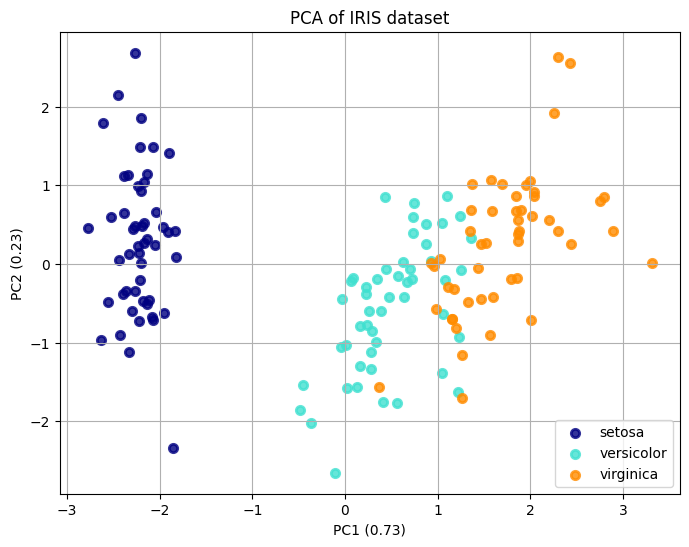

In [4]:
plt.figure(figsize=(8, 6))
colors = ['navy', 'turquoise', 'darkorange']
for color, i, target_name in zip(colors, [0, 1, 2], target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], color=color, alpha=.8, lw=2,
                label=target_name)
plt.legend(loc='best', shadow=False, scatterpoints=1)
plt.title('PCA of IRIS dataset')
plt.xlabel(f'PC1 ({variance_ratio[0]:.2f})')
plt.ylabel(f'PC2 ({variance_ratio[1]:.2f})')
plt.grid(True)
plt.show()

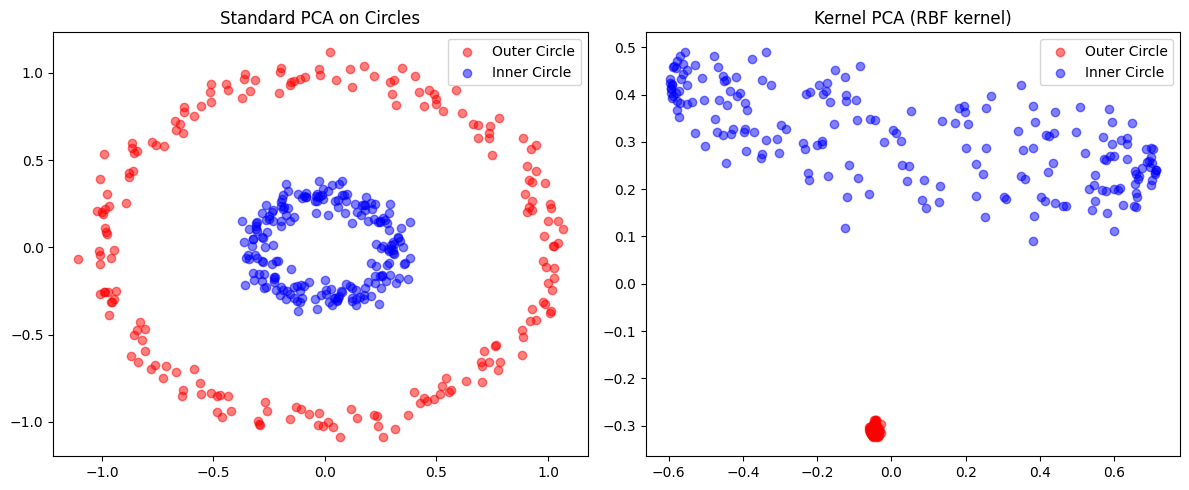

In [6]:
X_circles, y_circles = make_circles(n_samples=400, factor=.3, noise=.05, random_state=0)
pca_linear = PCA(n_components=2)
X_pca_linear = pca_linear.fit_transform(X_circles)
kpca = KernelPCA(kernel="rbf", gamma=10)
X_kpca = kpca.fit_transform(X_circles)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_pca_linear[y_circles == 0, 0], X_pca_linear[y_circles == 0, 1], color='red', alpha=0.5, label='Outer Circle')
plt.scatter(X_pca_linear[y_circles == 1, 0], X_pca_linear[y_circles == 1, 1], color='blue', alpha=0.5, label='Inner Circle')
plt.title("Standard PCA on Circles")
plt.legend()
plt.subplot(1, 2, 2)
plt.scatter(X_kpca[y_circles == 0, 0], X_kpca[y_circles == 0, 1], color='red', alpha=0.5, label='Outer Circle')
plt.scatter(X_kpca[y_circles == 1, 0], X_kpca[y_circles == 1, 1], color='blue', alpha=0.5, label='Inner Circle')
plt.title("Kernel PCA (RBF kernel)")
plt.legend()
plt.tight_layout()
plt.show()

8

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB
None

First 5 rows:
    age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203  

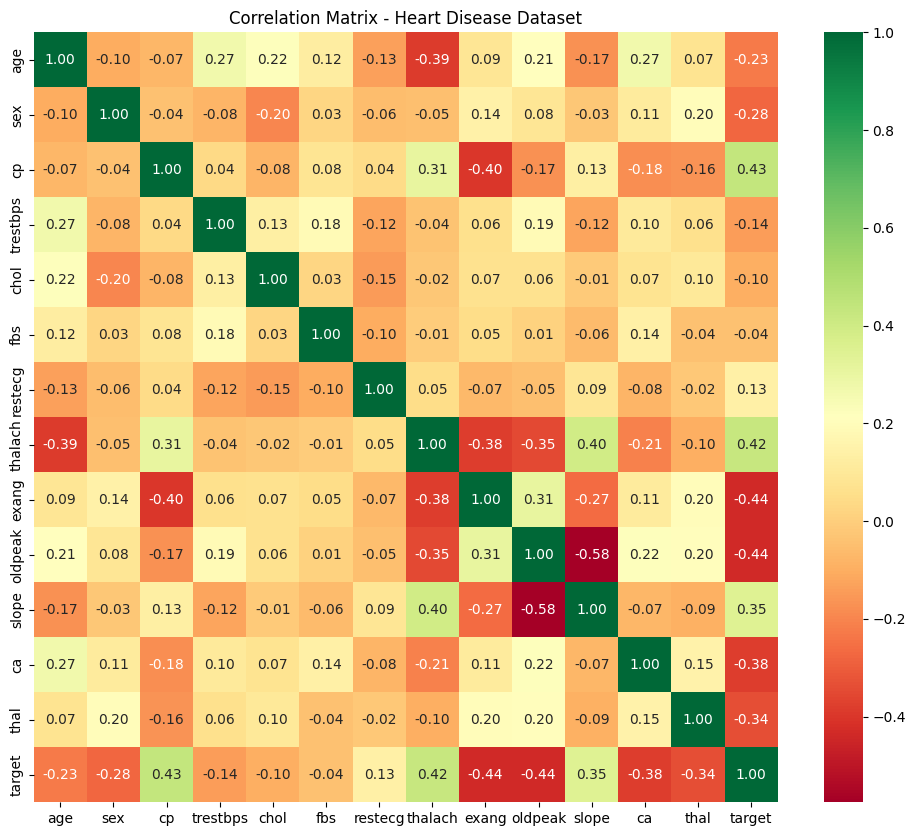

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('heart.csv')
print(df.info())
print("\nFirst 5 rows:\n", df.head())
plt.figure(figsize=(12, 10))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='RdYlGn', fmt='.2f')
plt.title("Correlation Matrix - Heart Disease Dataset")
plt.show()
X = df.drop('target', axis=1)
y = df['target']

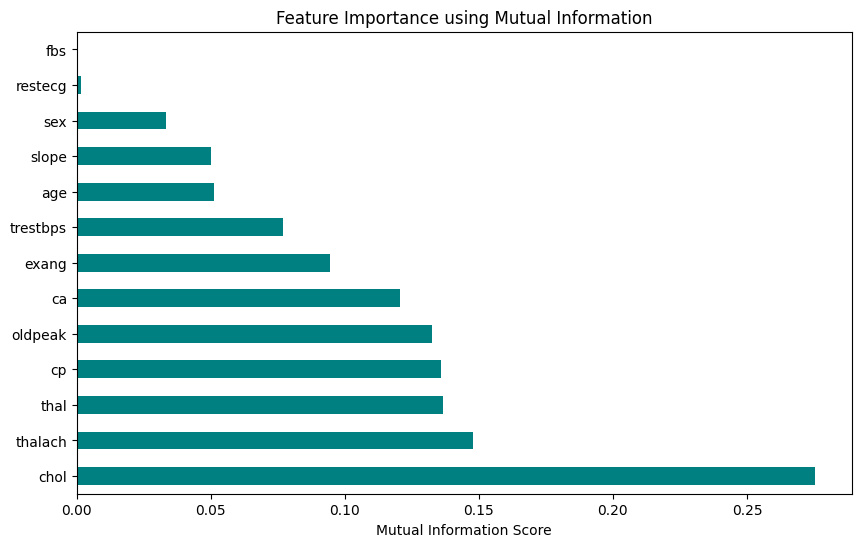

Top 5 Features by MI:
 chol       0.275314
thalach    0.147683
thal       0.136632
cp         0.135838
oldpeak    0.132645
dtype: float64


In [8]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(X, y, random_state=42)
mi_results = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
mi_results.plot(kind='barh', color='teal')
plt.title("Feature Importance using Mutual Information")
plt.xlabel("Mutual Information Score")
plt.show()

print("Top 5 Features by MI:\n", mi_results.head(5))

RFE Selected Features: ['sex', 'cp', 'thalach', 'oldpeak', 'ca']
Optimal number of features: 12


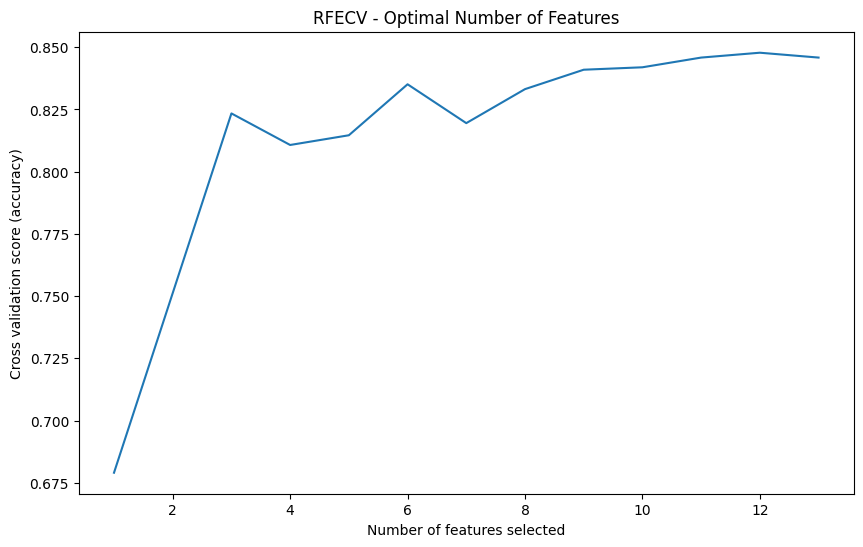

In [9]:
from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

model = LogisticRegression(max_iter=1000)
rfe = RFE(estimator=model, n_features_to_select=5)
rfe.fit(X_scaled, y)

print("RFE Selected Features:", list(X.columns[rfe.support_]))

rfecv = RFECV(estimator=model, step=1, cv=StratifiedKFold(5), scoring='accuracy')
rfecv.fit(X_scaled, y)

print(f"Optimal number of features: {rfecv.n_features_}")

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'])
plt.xlabel("Number of features selected")
plt.ylabel("Cross validation score (accuracy)")
plt.title("RFECV - Optimal Number of Features")
plt.show()

Lasso Important Features:
 cp          0.113528
ca          0.097130
sex         0.093679
oldpeak     0.072015
thal        0.070348
exang       0.067773
thalach     0.065585
slope       0.045222
trestbps    0.029415
restecg     0.021525
chol        0.021036
age         0.011894
dtype: float64


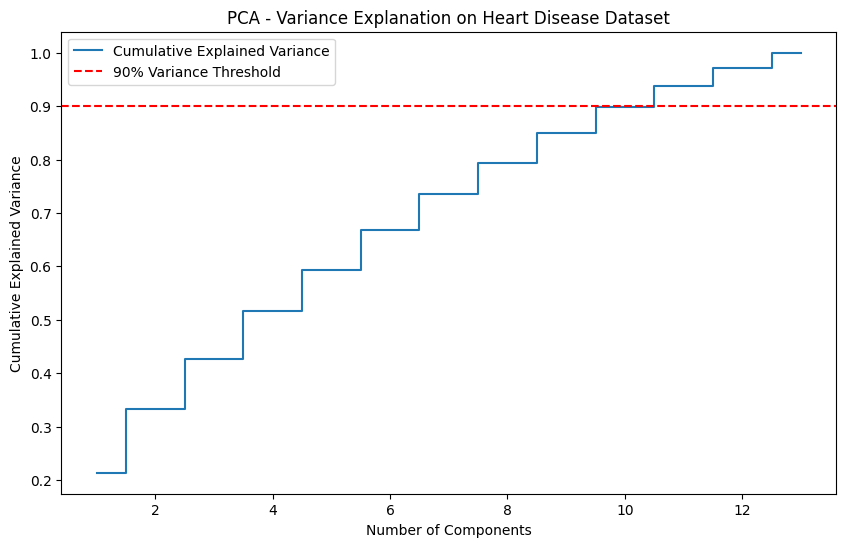

Number of PCA components to explain 90% variance: 11


In [10]:
from sklearn.linear_model import LassoCV

lasso = LassoCV(cv=5, random_state=42).fit(X_scaled, y)
lasso_coeffs = pd.Series(np.abs(lasso.coef_), index=X.columns).sort_values(ascending=False)

print("Lasso Important Features:\n", lasso_coeffs[lasso_coeffs > 0])

pca_heart = PCA().fit(X_scaled)
cum_variance = np.cumsum(pca_heart.explained_variance_ratio_)

plt.figure(figsize=(10, 6))
plt.step(range(1, len(cum_variance) + 1), cum_variance, where='mid', label='Cumulative Explained Variance')
plt.axhline(y=0.9, color='r', linestyle='--', label='90% Variance Threshold')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Variance Explanation on Heart Disease Dataset")
plt.legend()
plt.show()

n_90 = np.where(cum_variance >= 0.9)[0][0] + 1
print(f"Number of PCA components to explain 90% variance: {n_90}")

9

In [18]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import MinMaxScaler

def prepare_data(img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    rows, cols = np.indices((h, w))
    features = np.zeros((h * w, 5))
    features[:, :3] = img.reshape((-1, 3))
    features[:, 3] = rows.flatten()
    features[:, 4] = cols.flatten()
    scaler = MinMaxScaler()
    features_scaled = scaler.fit_transform(features)
    return img, features_scaled, (h, w)
img1, feat1, shape1 = prepare_data('image1.jpg')
print(f"5D Feature Vector Shape: {feat1.shape}")

5D Feature Vector Shape: (154401, 5)


In [19]:
def run_kmeans(features, shape, k):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(features)
    centers = kmeans.cluster_centers_[:, :3] 
    segmented_img = labels.reshape(shape)
    return segmented_img

def run_gmm(features, shape, k):
    gmm = GaussianMixture(n_components=k, random_state=42)
    labels = gmm.fit_predict(features)
    return labels.reshape(shape)


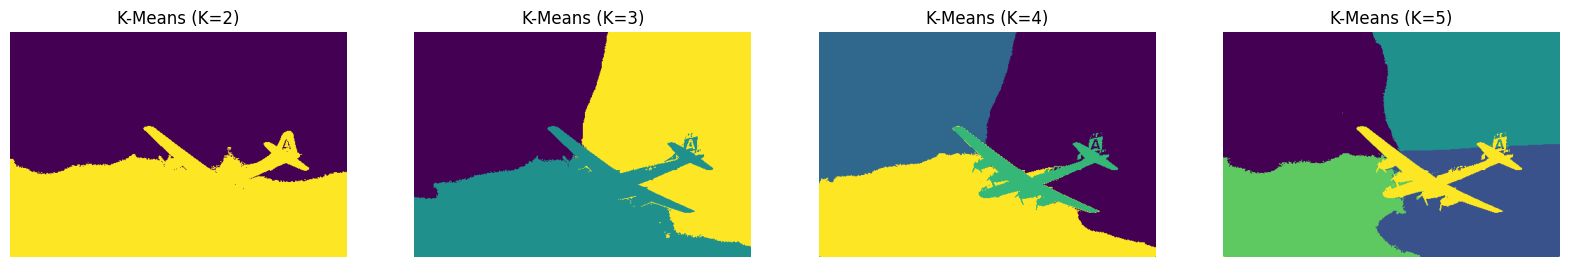

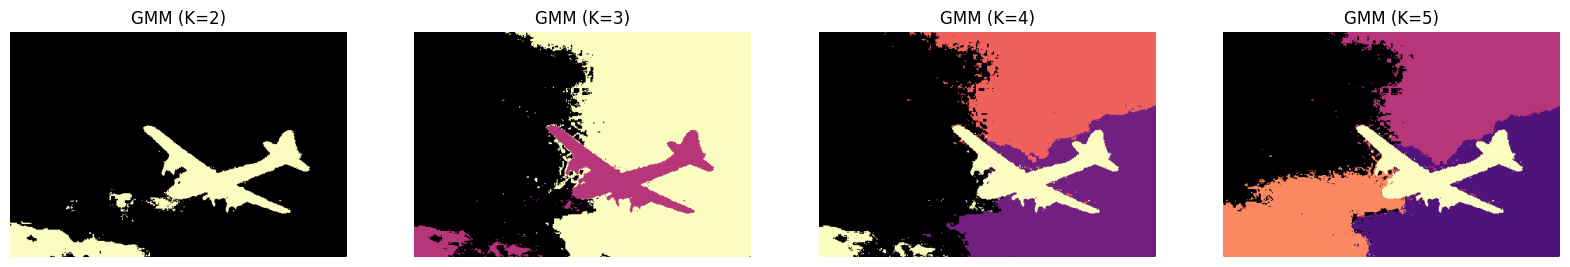

In [20]:
ks = [2, 3, 4, 5]
plt.figure(figsize=(20, 5))
for i, k in enumerate(ks):
    res = run_kmeans(feat1, shape1, k)
    plt.subplot(1, 4, i+1)
    plt.imshow(res, cmap='viridis')
    plt.title(f'K-Means (K={k})')
    plt.axis('off')
plt.show()

plt.figure(figsize=(20, 5))
for i, k in enumerate(ks):
    res = run_gmm(feat1, shape1, k)
    plt.subplot(1, 4, i+1)
    plt.imshow(res, cmap='magma')
    plt.title(f'GMM (K={k})')
    plt.axis('off')
plt.show()

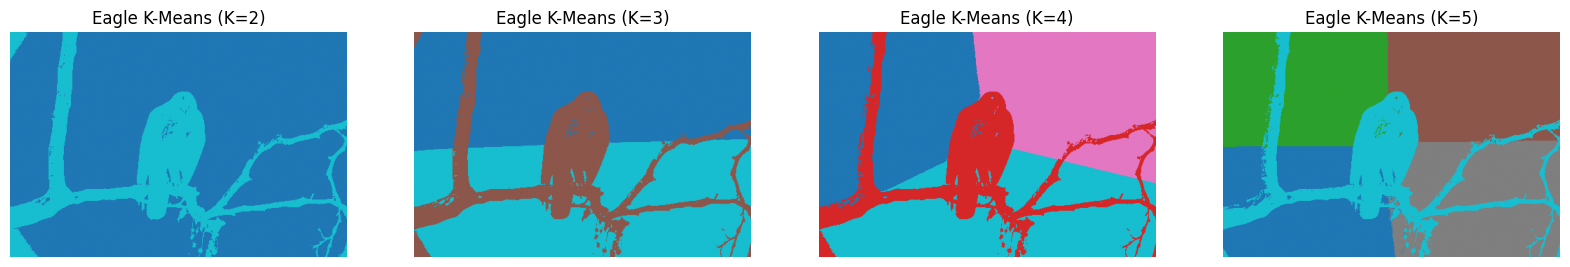

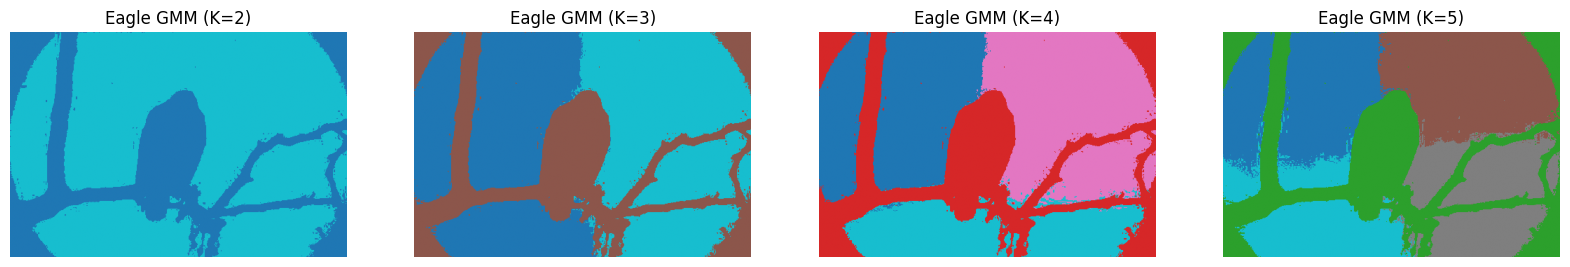

In [21]:
img2, feat2, shape2 = prepare_data('image2.jpg')
plt.figure(figsize=(20, 5))
for i, k in enumerate([2, 3, 4, 5]):
    res_km = run_kmeans(feat2, shape2, k)
    plt.subplot(1, 4, i+1)
    plt.imshow(res_km, cmap='tab10')
    plt.title(f'Eagle K-Means (K={k})')
    plt.axis('off')
plt.show()
plt.figure(figsize=(20, 5))
for i, k in enumerate([2, 3, 4, 5]):
    res_gmm = run_gmm(feat2, shape2, k)
    plt.subplot(1, 4, i+1)
    plt.imshow(res_gmm, cmap='tab10')
    plt.title(f'Eagle GMM (K={k})')
    plt.axis('off')
plt.show()